# ARTI 502 – Deep Learning: Assignment 2
## Training and Testing a CNN on the CIFAR Dataset with PyTorch
**Year 2026 – Term 1**

**Group #:**  1  **Members:** Reena Aloraini, Maria Aljafri, Wala Almukhtar, Rawan Alzaid, Dima Alrahal, Sara Alsahli




## Setup – imports and device

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [3]:
import os, time, json, random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as T

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch :", torch.__version__)
print("Device  :", device)

PyTorch : 2.14.1+cu130
Device  : cuda


## Task 1: Getting the CIFAR Dataset

In [4]:
DATA_PATH = "Dataset"         
os.makedirs(DATA_PATH, exist_ok=True)

CLASSES = ('airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

raw_trainset = torchvision.datasets.CIFAR10(root=DATA_PATH, train=True,
                                            download=True, transform=T.ToTensor())
raw_testset  = torchvision.datasets.CIFAR10(root=DATA_PATH, train=False,
                                            download=True, transform=T.ToTensor())

print("Dataset loaded successfully!")
print("Training samples :", len(raw_trainset))
print("Test samples     :", len(raw_testset))
print("Classes          :", raw_trainset.classes)

100%|██████████| 170M/170M [01:36<00:00, 1.76MB/s] 


Dataset loaded successfully!
Training samples : 50000
Test samples     : 10000
Classes          : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Task 2: Defining the Network
Two networks are defined so we can compare them in Task 5.

In [5]:
class SimpleCNN(nn.Module):
    """Baseline: 3 x (Conv -> ReLU -> MaxPool) followed by a 2-layer classifier."""
    def __init__(self, num_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)    # 3x32x32  -> 32x32x32
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)   # 32x16x16 -> 64x16x16
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)  # 64x8x8   -> 128x8x8
        self.pool  = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1   = nn.Linear(128 * 4 * 4, 256)
        self.fc2   = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # -> 32 x 16 x 16
        x = self.pool(F.relu(self.conv2(x)))   # -> 64 x 8 x 8
        x = self.pool(F.relu(self.conv3(x)))   # -> 128 x 4 x 4
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


class DeepCNN(nn.Module):
    """Improved: 3 blocks of (Conv-BN-ReLU) x2 -> MaxPool -> Dropout, then a classifier."""
    def __init__(self, num_classes=10, dropout=0.3):
        super().__init__()
        def block(c_in, c_out, p):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(c_out),
                nn.ReLU(inplace=True),
                nn.Conv2d(c_out, c_out, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(c_out),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
                nn.Dropout(p),
            )
        self.features = nn.Sequential(
            block(3, 64, dropout * 0.5),      # 64  x 16 x 16
            block(64, 128, dropout * 0.75),   # 128 x 8 x 8
            block(128, 256, dropout),         # 256 x 4 x 4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def build_model(name):
    return {"simple": SimpleCNN, "deep": DeepCNN}[name]().to(device)

In [6]:
# checking output shape and parameter count of each network
dummy = torch.randn(4, 3, 32, 32).to(device)
for name in ["simple", "deep"]:
    m = build_model(name)
    n_params = sum(p.numel() for p in m.parameters())
    print(f"{name:7s} output shape: {tuple(m(dummy).shape)}   parameters: {n_params:,}")
print()
print(build_model("simple"))

simple  output shape: (4, 10)   parameters: 620,362
deep    output shape: (4, 10)   parameters: 3,249,098

SimpleCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


### Training and test functions

In [7]:
def train_one_epoch(model, loader, criterion, optimizer, scheduler=None):
    model.train()
    running_loss, total = 0.0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        if scheduler is not None:          # OneCycleLR is stepped every batch
            scheduler.step()

        running_loss += loss.item() * images.size(0)
        total += images.size(0)
    return running_loss / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        running_loss += criterion(outputs, labels).item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += images.size(0)
    return running_loss / total, 100.0 * correct / total

## Task 3: Loading Data

In [8]:
viz_loader = DataLoader(raw_trainset, batch_size=16, shuffle=True, num_workers=2)
images, labels = next(iter(viz_loader))

print("Images tensor size :", images.shape)    # [batch, channels, height, width]
print("Labels tensor size :", labels.shape)
print("Pixel value range  : %.2f to %.2f" % (images.min().item(), images.max().item()))
print("dtype              :", images.dtype)

Images tensor size : torch.Size([16, 3, 32, 32])
Labels tensor size : torch.Size([16])
Pixel value range  : 0.00 to 1.00
dtype              : torch.float32


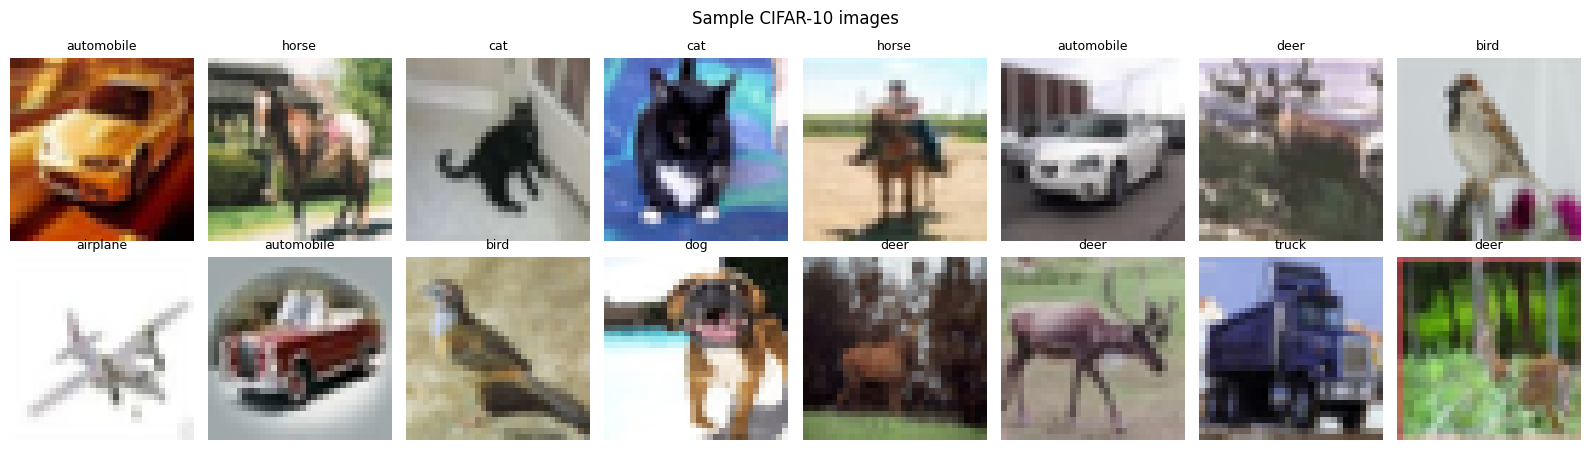

In [9]:
def show_batch(images, labels, n=16, mean=None, std=None, title="Sample CIFAR-10 images"):
    images = images[:n].clone()
    if mean is not None:
        images = images * torch.tensor(std).view(1, 3, 1, 1) + torch.tensor(mean).view(1, 3, 1, 1)
    images = images.clamp(0, 1)
    fig, axes = plt.subplots(2, n // 2, figsize=(2 * n // 2, 4.6))
    for ax, img, lbl in zip(axes.flat, images, labels[:n]):
        ax.imshow(img.permute(1, 2, 0).numpy())      # CxHxW -> HxWxC for matplotlib
        ax.set_title(CLASSES[lbl], fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_batch(images, labels)

## Task 4: Dataset Augmentation

In [10]:
MEAN = (0.4914, 0.4822, 0.4465)    # CIFAR-10 channel means
STD  = (0.2470, 0.2435, 0.2616)    # CIFAR-10 channel standard deviations

class AddGaussianNoise:
    def __init__(self, std=0.03, p=0.5):
        self.std, self.p = std, p
    def __call__(self, x):
        if random.random() < self.p:
            x = (x + torch.randn_like(x) * self.std).clamp(0, 1)
        return x

class AddSaltPepperNoise:
    def __init__(self, amount=0.01, p=0.3):
        self.amount, self.p = amount, p
    def __call__(self, x):
        if random.random() < self.p:
            mask = torch.rand(1, x.shape[1], x.shape[2])
            x = x.clone()
            x[:, (mask < self.amount / 2)[0]] = 0.0
            x[:, (mask > 1 - self.amount / 2)[0]] = 1.0
        return x

# Data augmentation for training data
train_transform = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomResizedCrop(32, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    T.RandomRotation(degrees=10),
    T.ToTensor(),                       # PIL (HxWxC) -> tensor (CxHxW) in [0, 1]
    AddGaussianNoise(std=0.03, p=0.5),
    AddSaltPepperNoise(amount=0.01, p=0.3),
    T.Normalize(MEAN, STD),
])

# Data augmentation for testing data
test_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

#(no augmentation) used for comparison
plain_transform = test_transform

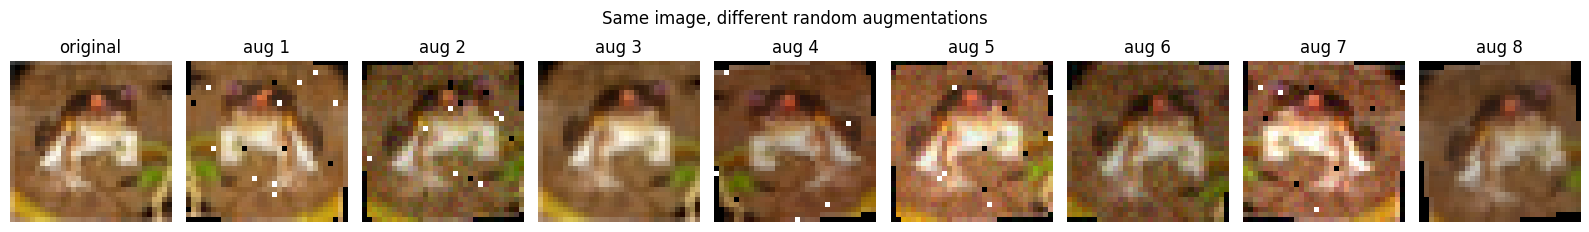

In [ ]:
# Demonstration
raw_np = raw_trainset.data[0] # uint8 array, shape (32, 32, 3)
demo_aug = T.Compose([T.ToPILImage(), *train_transform.transforms[:-1]])   # everything except Normalize

fig, axes = plt.subplots(1, 9, figsize=(16, 2.4))
axes[0].imshow(raw_np); axes[0].set_title("original"); axes[0].axis("off")
for i in range(1, 9):
    aug_img = demo_aug(raw_np)    # a different random augmentation each call
    axes[i].imshow(aug_img.permute(1, 2, 0).numpy()); axes[i].set_title(f"aug {i}"); axes[i].axis("off")
plt.suptitle("Same image, different random augmentations")
plt.tight_layout(); plt.show()

Augmented batch size: torch.Size([16, 3, 32, 32])


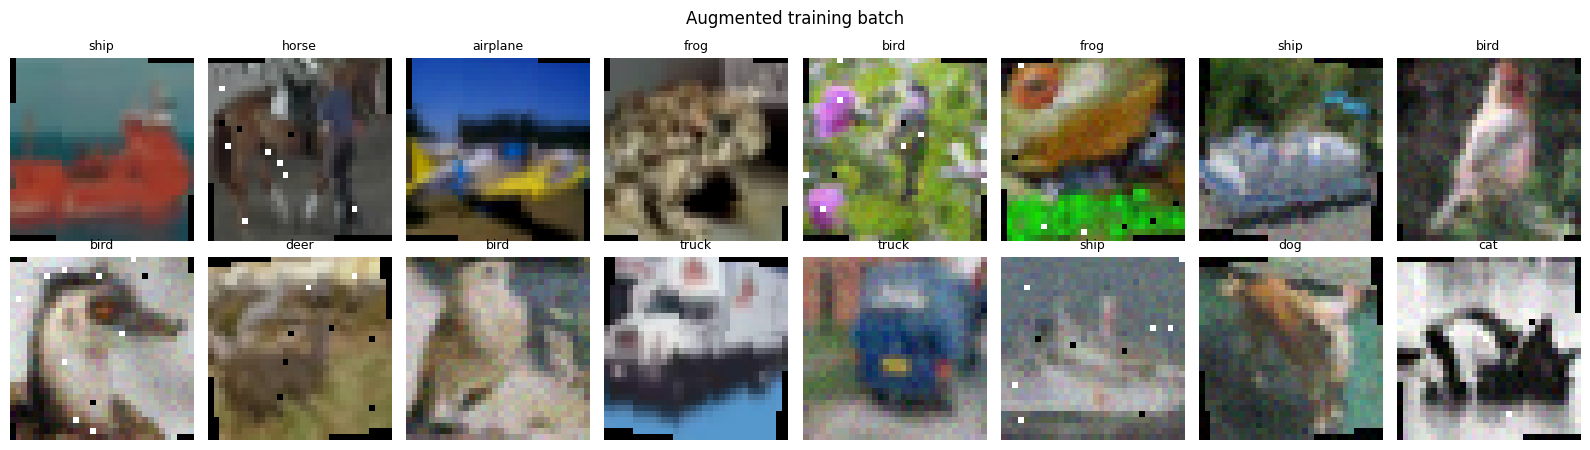

In [ ]:
# Visualise an augmented training batch (we must un-normalised for display)
aug_trainset = torchvision.datasets.CIFAR10(DATA_PATH, train=True, download=False, transform=train_transform)
aug_loader = DataLoader(aug_trainset, batch_size=16, shuffle=True, num_workers=2)
aug_imgs, aug_lbls = next(iter(aug_loader))
print("Augmented batch size:", aug_imgs.shape)
show_batch(aug_imgs, aug_lbls, mean=MEAN, std=STD, title="Augmented training batch")

## Task 5: Training Function and Tuning Hyperparameters

In [13]:
def make_loaders(batch_size, augment):
    tr_tf = train_transform if augment else plain_transform
    trainset = torchvision.datasets.CIFAR10(DATA_PATH, train=True,  download=False, transform=tr_tf)
    testset  = torchvision.datasets.CIFAR10(DATA_PATH, train=False, download=False, transform=test_transform)
    train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True,  num_workers=2, pin_memory=True)
    test_loader  = DataLoader(testset,  batch_size=256,        shuffle=False, num_workers=2, pin_memory=True)
    return train_loader, test_loader


def fit(model, train_loader, test_loader, epochs, optimizer, scheduler=None, verbose=True):
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "test_loss": [], "test_acc": []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss = train_one_epoch(model, train_loader, criterion, optimizer, scheduler)
        te_loss, te_acc = evaluate(model, test_loader, criterion)
        history["train_loss"].append(tr_loss)
        history["test_loss"].append(te_loss)
        history["test_acc"].append(te_acc)
        if verbose:
            print(f"Epoch {epoch:3d}/{epochs} | train loss {tr_loss:.4f} | "
                  f"test loss {te_loss:.4f} | test acc {te_acc:6.2f}% | {time.time()-t0:.1f}s")
    return history


def run_experiment(cfg, verbose=True):
    torch.manual_seed(SEED)
    train_loader, test_loader = make_loaders(cfg["batch_size"], cfg["augment"])
    model = build_model(cfg["model"])

    if cfg["optimizer"] == "adam":
        optimizer = optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg.get("wd", 5e-4))
    else:
        optimizer = optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9,
                              weight_decay=cfg.get("wd", 5e-4), nesterov=True)

    scheduler = None
    if cfg.get("onecycle", False):
        scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=cfg["lr"],
                        epochs=cfg["epochs"], steps_per_epoch=len(train_loader))

    print(f"\n=== {cfg['name']} ===")
    history = fit(model, train_loader, test_loader, cfg["epochs"], optimizer, scheduler, verbose)
    return model, history

In [14]:
def plot_history(history, title="Training results"):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].plot(epochs, history["train_loss"], "o-", color="tab:blue");   ax[0].set_title("Training loss")
    ax[1].plot(epochs, history["test_loss"],  "o-", color="tab:orange"); ax[1].set_title("Test loss")
    ax[2].plot(epochs, history["test_acc"],   "o-", color="tab:green");  ax[2].set_title("Test accuracy (%)")
    for a in ax:
        a.set_xlabel("Epoch"); a.grid(alpha=0.3)
    fig.suptitle(title); plt.tight_layout(); plt.show()

### Experiments
Each experiment changes one thing at a time (augmentation, architecture, optimiser/learning-rate schedule) so the
effect can be attributed. Short runs (10 epochs) are used for the comparison; the best design is then trained longer
in the final run. 

In [15]:
experiments = [
    dict(name="E1: SimpleCNN, no augmentation, AdamW lr=1e-3",
         model="simple", augment=False, optimizer="adam", lr=1e-3, batch_size=128, epochs=10),
    dict(name="E2: SimpleCNN, augmentation, AdamW lr=1e-3",
         model="simple", augment=True,  optimizer="adam", lr=1e-3, batch_size=128, epochs=10),
    dict(name="E3: DeepCNN, augmentation, AdamW lr=1e-3",
         model="deep",   augment=True,  optimizer="adam", lr=1e-3, batch_size=128, epochs=10),
    dict(name="E4: DeepCNN, augmentation, SGD+OneCycle lr=0.05",
         model="deep",   augment=True,  optimizer="sgd",  lr=0.05, batch_size=128, epochs=10, onecycle=True),
    dict(name="E5: DeepCNN, augmentation, AdamW+OneCycle lr=3e-3, bs=256",
         model="deep",   augment=True,  optimizer="adam", lr=3e-3, batch_size=256, epochs=10, onecycle=True),
]

results = {}
for cfg in experiments:
    _, hist = run_experiment(cfg, verbose=False)
    results[cfg["name"]] = hist
    print(f"   final train loss {hist['train_loss'][-1]:.4f} | test loss {hist['test_loss'][-1]:.4f} "
          f"| test acc {hist['test_acc'][-1]:.2f}%  (best {max(hist['test_acc']):.2f}%)")


=== E1: SimpleCNN, no augmentation, AdamW lr=1e-3 ===
   final train loss 0.1902 | test loss 0.9614 | test acc 75.51%  (best 76.25%)

=== E2: SimpleCNN, augmentation, AdamW lr=1e-3 ===
   final train loss 0.6886 | test loss 0.6749 | test acc 77.30%  (best 77.30%)

=== E3: DeepCNN, augmentation, AdamW lr=1e-3 ===
   final train loss 0.7719 | test loss 0.6365 | test acc 78.76%  (best 78.81%)

=== E4: DeepCNN, augmentation, SGD+OneCycle lr=0.05 ===
   final train loss 0.5807 | test loss 0.4815 | test acc 83.65%  (best 83.65%)

=== E5: DeepCNN, augmentation, AdamW+OneCycle lr=3e-3, bs=256 ===
   final train loss 0.5598 | test loss 0.4699 | test acc 84.10%  (best 84.10%)


Experiment                                                        Train loss  Test loss  Test acc %
E1: SimpleCNN, no augmentation, AdamW lr=1e-3                         0.1902     0.9614       75.51
E2: SimpleCNN, augmentation, AdamW lr=1e-3                            0.6886     0.6749       77.30
E3: DeepCNN, augmentation, AdamW lr=1e-3                              0.7719     0.6365       78.76
E4: DeepCNN, augmentation, SGD+OneCycle lr=0.05                       0.5807     0.4815       83.65
E5: DeepCNN, augmentation, AdamW+OneCycle lr=3e-3, bs=256             0.5598     0.4699       84.10


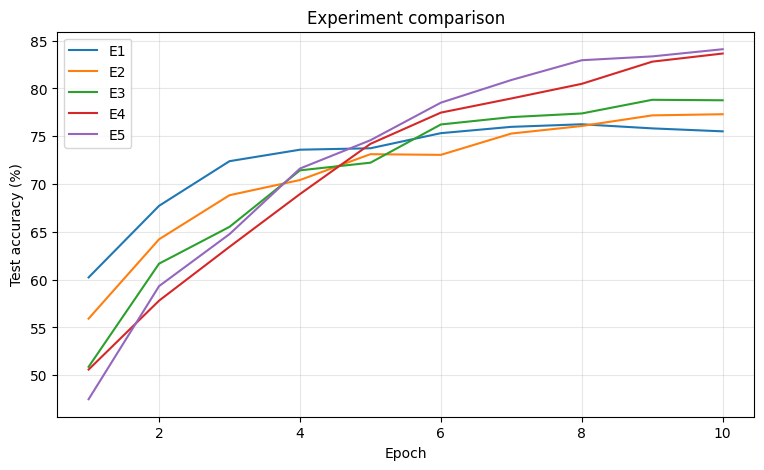

In [16]:
# Comparison table + plot of all experiments
print(f"{'Experiment':65s} {'Train loss':>10s} {'Test loss':>10s} {'Test acc %':>11s}")
for name, h in results.items():
    print(f"{name:65s} {h['train_loss'][-1]:10.4f} {h['test_loss'][-1]:10.4f} {h['test_acc'][-1]:11.2f}")

plt.figure(figsize=(9, 5))
for name, h in results.items():
    plt.plot(range(1, len(h["test_acc"]) + 1), h["test_acc"], label=name.split(":")[0])
plt.xlabel("Epoch"); plt.ylabel("Test accuracy (%)"); plt.title("Experiment comparison")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### Final run with the best design


=== FINAL: DeepCNN, augmentation, AdamW+OneCycle lr=3e-3, bs=256 ===
Epoch   1/30 | train loss 1.7295 | test loss 1.3145 | test acc  51.47% | 50.0s
Epoch   2/30 | train loss 1.3733 | test loss 1.1551 | test acc  59.56% | 50.0s
Epoch   3/30 | train loss 1.1687 | test loss 0.9309 | test acc  66.95% | 50.9s
Epoch   4/30 | train loss 1.0633 | test loss 0.9047 | test acc  68.52% | 50.6s
Epoch   5/30 | train loss 1.0081 | test loss 0.9902 | test acc  66.25% | 50.1s
Epoch   6/30 | train loss 0.9666 | test loss 0.7500 | test acc  74.15% | 49.0s
Epoch   7/30 | train loss 0.9020 | test loss 0.8028 | test acc  73.16% | 50.0s
Epoch   8/30 | train loss 0.8376 | test loss 0.6962 | test acc  76.11% | 50.3s
Epoch   9/30 | train loss 0.7696 | test loss 0.7926 | test acc  73.92% | 49.1s
Epoch  10/30 | train loss 0.7102 | test loss 0.7584 | test acc  75.73% | 50.4s
Epoch  11/30 | train loss 0.6740 | test loss 0.5532 | test acc  81.34% | 50.9s
Epoch  12/30 | train loss 0.6338 | test loss 0.4980 | test ac

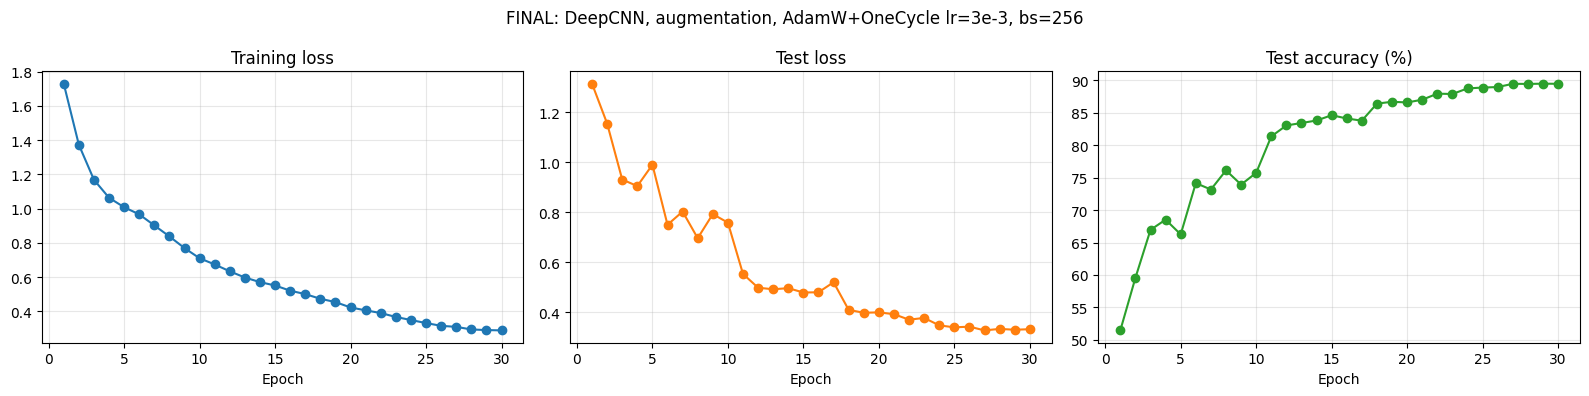


--- Final results ---
Final train loss : 0.2891
Final test loss  : 0.3320
Final test acc   : 89.44%
Best test acc    : 89.46%


In [17]:
BEST = dict(experiments[4])           
BEST.update(name="FINAL: " + BEST["name"].split(": ")[1], epochs=30)

final_model, final_hist = run_experiment(BEST)
plot_history(final_hist, title=BEST["name"])

print("\n--- Final results ---")
print(f"Final train loss : {final_hist['train_loss'][-1]:.4f}")
print(f"Final test loss  : {final_hist['test_loss'][-1]:.4f}")
print(f"Final test acc   : {final_hist['test_acc'][-1]:.2f}%")
print(f"Best test acc    : {max(final_hist['test_acc']):.2f}%")

In [18]:
# Per-class accuracy of the final model
_, test_loader = make_loaders(256, augment=False)
final_model.eval()
correct, total = [0]*10, [0]*10
with torch.no_grad():
    for x, y in test_loader:
        pred = final_model(x.to(device)).argmax(1).cpu()
        for t, p in zip(y, pred):
            total[t] += 1; correct[t] += int(t == p)
for i, c in enumerate(CLASSES):
    print(f"{c:11s}: {100*correct[i]/total[i]:5.1f}%")

airplane   :  91.5%
automobile :  96.6%
bird       :  84.0%
cat        :  72.3%
deer       :  90.4%
dog        :  81.0%
frog       :  95.5%
horse      :  94.3%
ship       :  94.5%
truck      :  94.3%


## Task 6: Save Your Source Code

In [19]:
torch.save(final_model.state_dict(), "cifar10_best_model.pt")
with open("training_history.json", "w") as f:
    json.dump({"config": BEST, "history": final_hist, "all_experiments": results}, f, indent=2)
print("Saved: cifar10_best_model.pt, training_history.json")

Saved: cifar10_best_model.pt, training_history.json
